**Greedy Search**

A fairly obvious way is to simply predict the word in the last layer that has the highest probability.

---


**Beam Search**

Beam Search makes two improvements over Greedy Search.

Beam search is a heuristic search algorithm that explores a graph (in this case, the sequence space) by expanding only the top k most promising hypotheses (called "beams") at each decoding step, rather than just the single best one (as in greedy decoding) or all possible ones (as in exhaustive search). In sequence generation (e.g. language modeling or translation), it’s used to keep multiple likely output sequences and select the most probable one at the end.

With Greedy Search, we took just the single best word at each position. In contrast, Beam Search expands this and takes the best ‘N’ words.

With Greedy Search, we considered each position in the sequence in isolation. Once we had identified the best word for that position, we did not examine what came before it (ie. in the previous position), or after it. In contrast, Beam Search picks the ‘N’ best sequences so far and considers the probabilities of the combination of all of the preceding words along with the word in the current position.
In other words, it is casting the "light beam of its search" a little more broadly than Greedy Search, and this is what gives it its name. The hyperparameter ‘N’ is known as the **Beam width**.

Intuitively it makes sense that this gives us better results over Greedy Search. Because, what we are really interested in is the best complete sentence, and we might miss that if we picked only the best individual word in each position as in greedy.

Eg: Beam search decoding with beam width 2.

Consider the output of the model at the first position. It starts with the "sos/start" token and obtains probabilities for each word. It now selects the two best characters in that position. eg. "A" and "C". When it comes to the second position, it re-runs the model twice to generate probabilities by fixing the possible characters in the first position. In other words, it constrains the characters in the first position to be either an "A" or a "C" and generates two branches with two sets of probabilities. The branch with the first set of probabilities corresponds to having "A" in position 1, and the branch with the second set corresponds to having "C" in position 1. It now picks the overall two best character pairs based on the combined probability of the first two characters, from out of both sets of probabilities. So it doesn’t pick just one best character pair from the first set and one best character pair from the second set. eg. "AB" and "AE" When it comes to the third position, it repeats the process. It re-runs the model twice by constraining the first two positions to be either "AB" or "AE" and again generates two sets of probabilities.
Once more, it picks the overall two best character triplets based on the combined probability of the first three characters from both sets of probabilities. Therefore we now have the two best combinations of characters for the first three positions. eg. "ABC" and "AED". It continues doing this till it picks an "eos/end" token as the best character for some position, which then concludes that branch of the sequence. It finally ends up with the two best sequences and predicts the one with the higher overall probability.



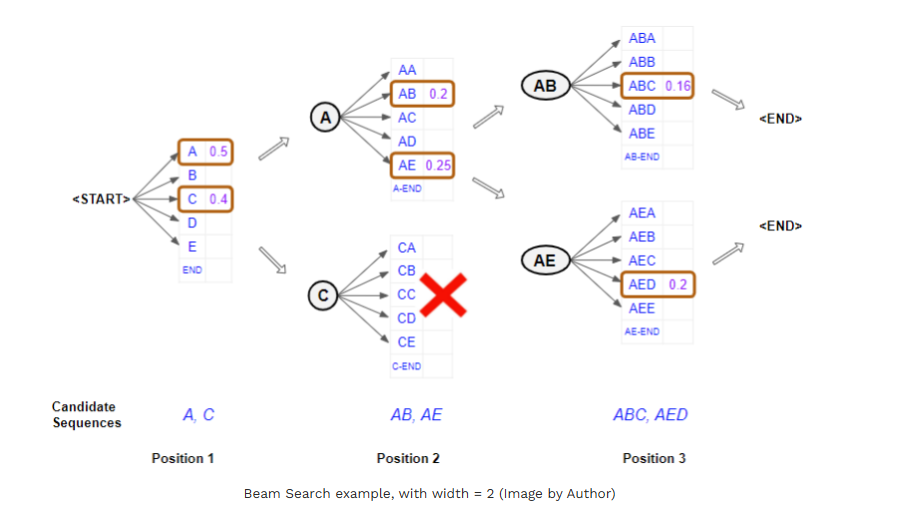

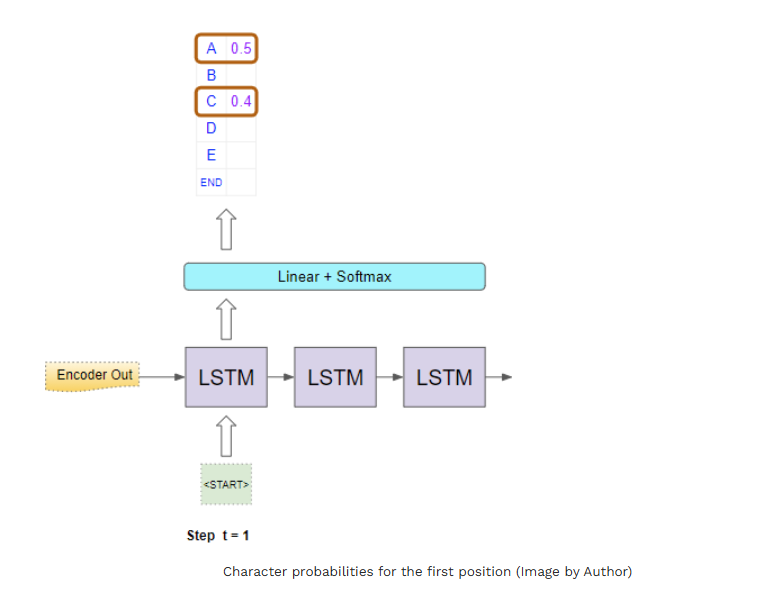

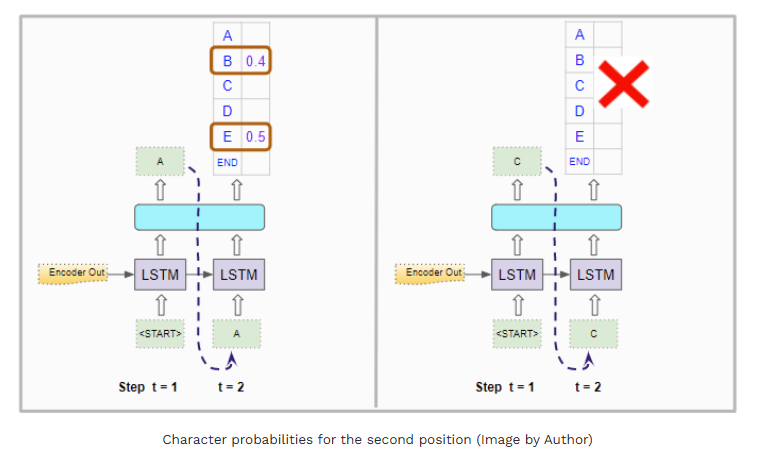

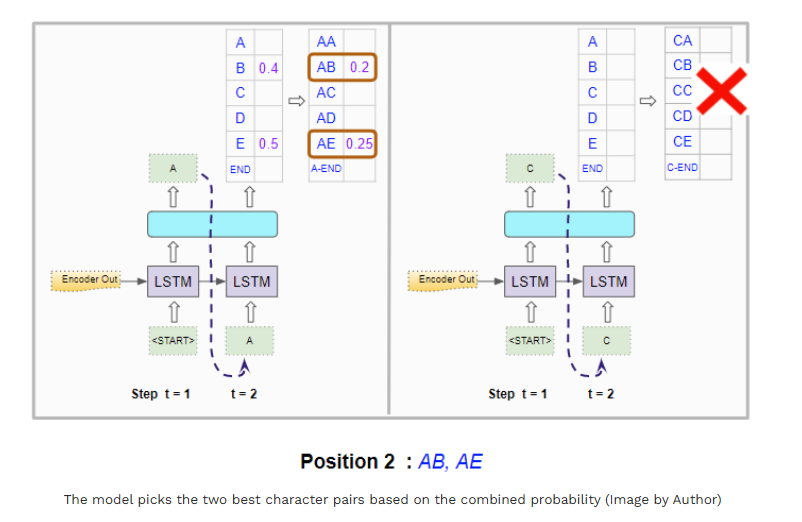

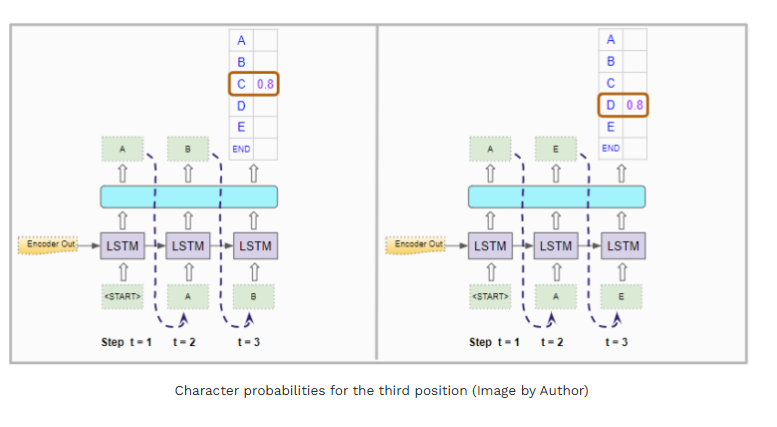

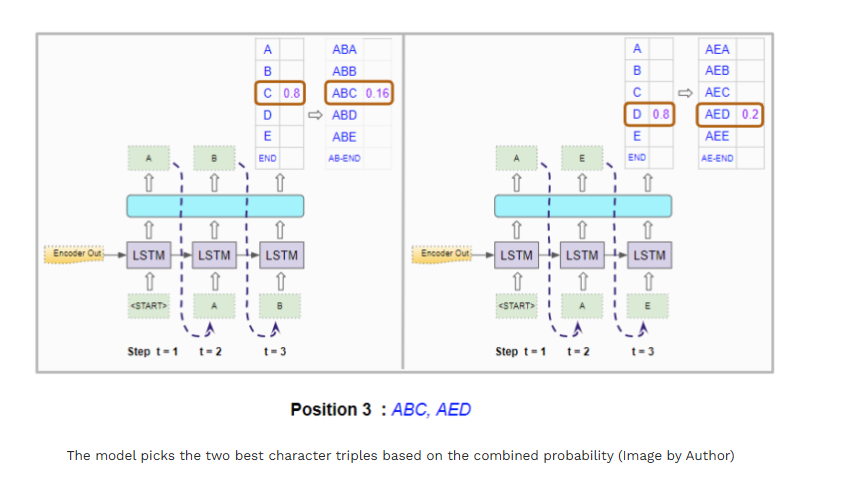

Note: For every position, we will run the decoder twice(based on beam depth) and everytime we calculate combined probabilities. Hence beam search is expensive.

In [1]:
!pip install torchtext torchdata --index-url https://download.pytorch.org/whl/cu118

Looking in indexes: https://download.pytorch.org/whl/cu118
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 28.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 811.7/811.7 MB 1.4 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.7/4.7 MB 90.0 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.2/23.2 MB 90.2 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 875.6/875.6 kB 55.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.1/13.1 MB 130.8 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 728.5/728.5 MB 1.6 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 417.9/417.9 MB 3.1 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 168.4/168.4 MB 14.3 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.1/58.1 MB 13.2 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 128.2/128.2 MB 19.6 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 204.1/204

In [2]:
!pip install "numpy<2"

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.0/61.0 kB 2.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.3/18.3 MB 111.3 MB/s eta 0:00:00
  Attempting uninstall: numpy
    Found existing installation: numpy 2.0.2
    Uninstalling numpy-2.0.2:
      Successfully uninstalled numpy-2.0.2
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
torchvision 0.21.0+cu124 requires torch==2.6.0, but you have torch 2.2.0+cu118 which is incompatible.
thinc 8.3.6 requires numpy<3.0.0,>=2.0.0, but you have numpy 1.26.4 which is incompatible.
torchtune 0.6.1 requires torchdata==0.11.0, but you have torchdata 0.7.1 which is incompatible.


In [3]:
!pip install portalocker>=2.0.0

In [4]:
!pip install -U datasets huggingface_hub fsspec

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 491.5/491.5 kB 10.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 510.0/510.0 kB 36.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 193.6/193.6 kB 16.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.2/5.2 MB 100.7 MB/s eta 0:00:00
  Attempting uninstall: fsspec
    Found existing installation: fsspec 2025.3.2
    Uninstalling fsspec-2025.3.2:
      Successfully uninstalled fsspec-2025.3.2
  Attempting uninstall: huggingface_hub
    Found existing installation: huggingface-hub 0.31.2
    Uninstalling huggingface-hub-0.31.2:
      Successfully uninstalled huggingface-hub-0.31.2
  Attempting uninstall: datasets
    Found existing installation: datasets 2.14.4
    Uninstalling datasets-2.14.4:
      Successfully uninstalled datasets-2.14.4
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency 

In [5]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [1]:
import torch, torchtext, datasets

from torchtext.vocab import build_vocab_from_iterator
from torchtext.data.utils import get_tokenizer

from torch import nn as nn
import torch.nn.functional as F
from torch.nn.utils.rnn import pad_sequence, pack_padded_sequence, pad_packed_sequence

import torch.optim as optim
from torch.optim.lr_scheduler import ReduceLROnPlateau

from tqdm import tqdm
import math, time

seed = 1234
torch.manual_seed(1234)
torch.backends.cudnn.determinstic = True
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [2]:
# Load Dataset
dataset = datasets.load_dataset(path="Salesforce/wikitext", name="wikitext-2-raw-v1")
dataset

/usr/local/lib/python3.11/dist-packages/huggingface_hub/utils/_auth.py:104: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
You are not authenticated with the Hugging Face Hub in this notebook.
If the error persists, please let us know by opening an issue on GitHub (https://github.com/huggingface/huggingface_hub/issues/new).
  warnings.warn(


README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

test-00000-of-00001.parquet:   0%|          | 0.00/733k [00:00<?, ?B/s]

train-00000-of-00001.parquet:   0%|          | 0.00/6.36M [00:00<?, ?B/s]

validation-00000-of-00001.parquet:   0%|          | 0.00/657k [00:00<?, ?B/s]

Generating test split:   0%|          | 0/4358 [00:00<?, ? examples/s]

Generating train split:   0%|          | 0/36718 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/3760 [00:00<?, ? examples/s]

DatasetDict({
    test: Dataset({
        features: ['text'],
        num_rows: 4358
    })
    train: Dataset({
        features: ['text'],
        num_rows: 36718
    })
    validation: Dataset({
        features: ['text'],
        num_rows: 3760
    })
})

In [3]:
dataset["train"][233]["text"]

' The Flower Fairy Picture Book ; Blackie , 1955 \n'

In [4]:
# Tokenize
tokenizer = get_tokenizer("basic_english")

tokenization = lambda example, tokenizer: {"tokens": tokenizer(example["text"])}
dataset = dataset.map(tokenization, remove_columns="text", fn_kwargs={"tokenizer": tokenizer})

dataset

Map:   0%|          | 0/4358 [00:00<?, ? examples/s]

Map:   0%|          | 0/36718 [00:00<?, ? examples/s]

Map:   0%|          | 0/3760 [00:00<?, ? examples/s]

DatasetDict({
    test: Dataset({
        features: ['tokens'],
        num_rows: 4358
    })
    train: Dataset({
        features: ['tokens'],
        num_rows: 36718
    })
    validation: Dataset({
        features: ['tokens'],
        num_rows: 3760
    })
})

In [6]:
# Vocab to idx mappings
specials = ["<pad>", "<unk>", "<sos>", "<eos>"]

vocab = build_vocab_from_iterator(dataset["train"]["tokens"], min_freq=3, specials=specials, special_first=True)
vocab.set_default_index(vocab["<unk>"])

PAD_IDX, UNK_IDX, SOS_IDX, EOS_IDX = vocab["<pad>"], vocab["<unk>"], vocab["<sos>"], vocab["<eos>"]

idx2word_mapping = vocab.get_itos()

In [7]:
len(vocab), vocab["<unk>"], vocab["<pad>"], vocab["<sos>"], vocab["<eos>"], vocab.get_itos()[:10]

(29475,
 1,
 0,
 2,
 3,
 ['<pad>', '<unk>', '<sos>', '<eos>', 'the', ',', '.', 'of', 'and', 'in'])

In [8]:
# Numericalize and Flatten
def numericalize_flatten(data, vocab):
    """Flatten and numericalize => we get all docs/sentences flattened into single list for Language Modeling."""
    token_idxs = []
    for tokens in data["tokens"]:
        tokens.append("<eos>")
        token_idxs.extend([vocab[token] for token in tokens])
    return {"tokens": token_idxs}

train = dataset["train"].map(numericalize_flatten, batched=True, fn_kwargs={"vocab": vocab})
val = dataset["validation"].map(numericalize_flatten, batched=True, fn_kwargs={"vocab": vocab})
test = dataset["test"].map(numericalize_flatten, batched=True, fn_kwargs={"vocab": vocab})

Map:   0%|          | 0/36718 [00:00<?, ? examples/s]

Map:   0%|          | 0/3760 [00:00<?, ? examples/s]

Map:   0%|          | 0/4358 [00:00<?, ? examples/s]

In [9]:
train, val, test

(Dataset({
     features: ['tokens'],
     num_rows: 2088383
 }),
 Dataset({
     features: ['tokens'],
     num_rows: 218425
 }),
 Dataset({
     features: ['tokens'],
     num_rows: 246514
 }))

In [10]:
type(train["tokens"]), len(train["tokens"])

(list, 2088383)

In [13]:
# Prepare batches
def prepare_batches(data, batch_size):
    """Tensor conversion and get batches of even number of tokens"""
    data_tensor = torch.LongTensor(data["tokens"])  # shape: (len(tokens),)
    num_batches = data_tensor.shape[0] // batch_size # gives the evenly divided quotient i.e leaves out the data % batch_size remainder tokens
    # Make the batch evenly and leave out the remaining tokens
    data_tensor = data_tensor[:num_batches * batch_size]
    data_tensor = data_tensor.view(batch_size, num_batches)
    return data_tensor   # (bs, bunch of tokens) != (bs, seq_len)

In [14]:
# Get the batches
batch_size = 128

train_batches = prepare_batches(train, batch_size=batch_size)
val_batches = prepare_batches(val, batch_size=batch_size)
test_batches = prepare_batches(test, batch_size=batch_size)

In [16]:
train_batches.shape, val_batches.shape, test_batches.shape

(torch.Size([128, 16315]), torch.Size([128, 1706]), torch.Size([128, 1925]))

### Design the Transformer Model - Just the decoder

Note that this is not encoder decoder transformer(for seq2seq models) but just a decoder transformer to predict the next word in the sequence
- MultiHeadAttention
- PositionWiseFeedForward
- DecoderLayer
- Decoder

In a Decoder-only LM (e.g., GPT), there is no encoder. No cross attention from encoder context as in usual seq2seq encoder decoder transformers.Here, the decoder does only self-attention, with a causal mask (to prevent attending to future tokens). It models everything from left to right. The encoder context is implicitly replaced by the input prompt itself. The self-attention layer is responsible for modeling all dependencies — including "context" and "memory".

In [39]:
class MultiHeadAttention(nn.Module):
    def __init__(self, n_heads, hidden_dim, dropout, device):
        super().__init__()
        assert hidden_dim % n_heads == 0
        self.n_heads = n_heads
        self.hidden_dim = hidden_dim
        self.head_dim = hidden_dim // n_heads
        self.fc_q = nn.Linear(hidden_dim, hidden_dim)
        self.fc_k = nn.Linear(hidden_dim, hidden_dim)
        self.fc_v = nn.Linear(hidden_dim, hidden_dim)
        self.scale = torch.sqrt(torch.FloatTensor([self.head_dim])).to(device)

        self.fc_o = nn.Linear(hidden_dim, hidden_dim)
        self.dropout = nn.Dropout(dropout)
        self.device = device

    def forward(self, query, key, val, mask=None):
        # q = k = v = (bs, seq_len, hidden_dim)
        q = self.fc_q(query)   # (bs, q_seq_len, hidden_dim)
        k = self.fc_k(key)     # (bs, k_seq_len, hidden_dim)
        v = self.fc_v(val)     # (bs, v_seq_len, hidden_dim)
        bs = q.shape[0]

        q = q.view(bs, -1, self.n_heads, self.head_dim).permute(0, 2, 1, 3)  # (bs, q_seq_len, n_heads, head_dim) => (bs, n_heads, q_seq_len, head_dim)
        k = k.view(bs, -1, self.n_heads, self.head_dim).permute(0, 2, 1, 3)  # (bs, k_seq_len, n_heads, head_dim) => (bs, n_heads, k_seq_len, head_dim)
        v = v.view(bs, -1, self.n_heads, self.head_dim).permute(0, 2, 1, 3)  # (bs, v_seq_len, n_heads, head_dim) => (bs, n_heads, v_seq_len, head_dim)

        energy = torch.matmul(q, k.permute(0, 1, 3, 2)) / self.scale  # (bs, n_heads, q_seq_len, head_dim), (bs, n_heads, head_dim, k_seq_len) => (bs, n_heads, q_seq_len, k_seq_len)
        if mask is not None: # (bs, 1, seq_len, seq_len)
            energy = energy.masked_fill(mask==0, -1e10)  # (bs, n_heads, q_seq_len, k_seq_len)

        attn = torch.softmax(energy, dim=-1)      # (bs, n_heads, q_seq_len, k_seq_len)
        x = torch.matmul(self.dropout(attn), v)   # (bs, n_heads, q_seq_len, k_seq_len) (bs, n_heads, v_seq_len, head_dim) =>  (bs, n_heads, q_seq_len, head_dim)
        x = x.permute(0, 2, 1, 3).contiguous()    # (bs, q_seq_len, n_heads, head_dim)
        x = x.view(bs, -1, self.hidden_dim)       # (bs, q_seq_len, n_heads * head_dim) => (bs, q_seq_len, hidden_dim)
        x = self.fc_o(x)                          # (bs, q_seq_len, hidden_dim)
        return x, attn


In [40]:
class PositionWiseFeedForwardAttention(nn.Module):
    def __init__(self, pff_dim, hidden_dim, dropout):
        super().__init__()
        self.fc_1 = nn.Linear(hidden_dim, pff_dim)
        self.fc_2 = nn.Linear(pff_dim, hidden_dim)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        x = self.dropout(torch.relu(self.fc_1(x)))       # (bs, seq_len, hidden_dim) => (bs, seq_len, pff_dim)
        x = self.fc_2(x)                                 # (bs, seq_len, pff_dim) => (bs, seq_len, hidden_dim)
        return x

In [41]:
class DecoderLayer(nn.Module):
    def __init__(self, n_heads, hidden_dim, pff_dim, dropout, device):
        super().__init__()
        self.self_attention = MultiHeadAttention(n_heads, hidden_dim, dropout, device)
        self.self_attn_layer_norm = nn.LayerNorm(hidden_dim)
        self.pwffd = PositionWiseFeedForwardAttention(pff_dim, hidden_dim, dropout)
        self.ff_layer_norm = nn.LayerNorm(hidden_dim)
        self.dropout = nn.Dropout(dropout)

    def forward(self, seq, mask):

        # seq (bs, seq_len, hidden_dim)
        # mask (bs, 1, seq_len, seq_len)
        _seq, attn = self.self_attention(seq, seq, seq, mask)           # (bs, seq_len, hidden_dim), (bs, n_heads, q_seq_len, k_seq_len)
        seq = self.self_attn_layer_norm(self.dropout(_seq) + seq)
        _seq = self.pwffd(seq)                                          # (bs, seq_len, hidden_dim)
        output = self.ff_layer_norm(self.dropout(_seq) + seq)
        return output, attn

In [114]:
class Decoder(nn.Module):
    def __init__(self, voc_size, max_length, n_layers, n_heads, hidden_dim, pff_dim, dropout, device):
        super().__init__()
        self.token_embedding = nn.Embedding(num_embeddings=voc_size, embedding_dim=hidden_dim)
        self.pos_embedding = nn.Embedding(num_embeddings=max_length, embedding_dim=hidden_dim)
        self.layers = nn.ModuleList([DecoderLayer(n_heads, hidden_dim, pff_dim, dropout, device) for _ in range(n_layers)])
        self.fc_out = nn.Linear(in_features=hidden_dim, out_features=voc_size)
        self.dropout = nn.Dropout(dropout)
        self.scale = torch.sqrt(torch.FloatTensor([hidden_dim])).to(device)
        self.output_dim = voc_size
        self.pad_idx = PAD_IDX
        self.device = device

    def make_mask(self, seq):
        """This is called a causal mask (to prevent attending to future tokens)"""
        # seq: (bs, seq_len)
        seq_len = seq.shape[1]
        casual_mask = torch.tril(torch.ones((seq_len, seq_len), device=self.device)).bool()  # (seq_len, seq_len)
        pad_mask = (seq != self.pad_idx).unsqueeze(1).unsqueeze(2)  # (bs, 1, 1, seq_len)
        mask = casual_mask & pad_mask  # (seq_len, seq_len) & (bs, 1, 1, seq_len) => (bs, 1, seq_len, seq_len)
        return mask

    def forward(self, input_prompt_seq):
        # input_prompt_seq: (bs, seq_len)

        mask = self.make_mask(input_prompt_seq)   # (bs, 1, seq_len, seq_len)

        bs = input_prompt_seq.shape[0]
        seq_len = input_prompt_seq.shape[1]

        embeds = self.token_embedding(input_prompt_seq) * self.scale                # (bs, seq_len, hidden_dim)
        pos = torch.arange(0, seq_len).unsqueeze(0).repeat(bs, 1).to(self.device)  # (bs, seq_len)
        pos_embeds = self.pos_embedding(pos)                                        # (bs, seq_len, hidden_dim)

        input_embeds = self.dropout(embeds + pos_embeds)                            # (bs, seq_len, hidden_dim)

        for layer in self.layers:
            output, attn = layer(input_embeds, mask)                               # (bs, seq_len, hidden_dim), (bs, n_heads, q_seq_len, k_seq_len)

        logits = self.fc_out(output)                                                # (bs, seq_len, output_dim)
        return logits, attn

    def beam_decode(self, prompt="Harry Potter is ", beam_size=5, max_seq_len=5, penalty_alpha=0.9):
        # beam_size: Number of beams (hypotheses) to maintain at each step

        # Tokenize and convert prompt to tensor (starting with <sos>)
        tokens = [SOS_IDX] + [vocab[token] for token in tokenizer(prompt)]
        decoder_input = torch.Tensor([tokens]).long().to(device)             # (1, input_seq_len). Here shape[0] represents beam_size. Initially, there is one beam for the input prompt i.e  you're starting with just one prompt (one sequence), so you have one beam. In beam search, this 1 will become beam_size after the first expansion.
        beam_scores = torch.tensor([0.0], device=device)                     # Log-probability scores for each beam. Starts at 0.0 initially.
        # beam expansions
        max_gen_len = max_seq_len + len(tokens)                              # tokens from prompt + SOS
        for step in range(max_gen_len):
            # debugging
            # print(f"Step {step} sequences:")
            # for i, seq in enumerate(decoder_input):
            #     tokens = [vocab.lookup_token(t.item()) for t in seq]
            #     print(f"Beam {i}: {' '.join(tokens)}")
            # print(f"Beam scores: {beam_scores.tolist()}")

            # Forward pass for each beam
            logits, _ = self.forward(decoder_input)                       # shape: (beam_size, current_seq_len, vocab_size). Initially current_seq_len=>current_decoder_ldength = input seq len and then the seq expands
            logits = logits[:, -1]                                 # logits[:, -1, :] = logits[:, -1] => use logits from last time step: (beam_size, vocab_size)
            log_probs = torch.log_softmax(logits, dim=-1)          # (beam_size, vocab_size), gives you the log-probabilities of the next token for each beam in the beam search (e.g., if beam size = 5, and vocab_size = 10000, shape = (5, 10000)).Log softmax is better, since beam search accumulates probability, if its softmax, the probability can get too small and then become unstable
            # Apply length penalty
            length_penalty = ((5 + (step + 1)) / (5 + 1)) ** penalty_alpha             # Add length penalty, to avoid preferring short sequences, longer sequences are penalized less over time. see https://arxiv.org/abs/1609.08144
            log_probs /= length_penalty                                   # (beam_size, vocab_size)
            # Penalize bad outputs i.e Prevents beams from ending prematurely (<eos>) or generating <unk>. # ensures that sequences get a much lower score, effectively pushing the beam search away from generating <UNK> or <eos>
            last_tokens = decoder_input[:, -1]                    # (beam_size,)
            log_probs[last_tokens == EOS_IDX, :] = -2.0           # This means: for any beam where the last token is <EOS>, set all log-probabilities of the next token prediction to -2.0
            log_probs[last_tokens == UNK_IDX, :] = -10.0          # This means: for any beam where the last token is <UNK>, set all log-probabilities of the next token prediction to -10.0
            # Compute new candidate scores i.e get the top beams of beam_size
            total_scores = beam_scores.unsqueeze(1) + log_probs  # shape: (beam_size, vocab_size)  # Adds log-probs to previous beam scores. The scores are log-probabilities, and you're adding them up to compute the total log-probability of each sequence. This gives you the joint probability of the whole sequence so far.
            flat_scores = total_scores.view(-1)                  # shape: (beam_size * vocab_size) # Flattens the scores for all possible next tokens across all beams.
            top_scores, top_indices = torch.topk(flat_scores, beam_size)    # Picks the top beam_size best continuations overall. Return (Tensor, LongTensor) each of size beam_size
            # Get back beam and token indices
            next_beam_indices = top_indices // self.output_dim             # tells, from Which beam each top-scoring token came from.
            next_token_indices = top_indices % self.output_dim             # tells, Which token was selected
            # Build new beams i,e., Build the next decoder input. For efficiency, the trick is to concatenate all hypotheses into one string and sent to decoder at once
            next_decoder_input = []
            for beam_idx, token_idx in zip(next_beam_indices, next_token_indices):   # For each top candidate, Extend the corresponding previous sequence.
                prev_seq = decoder_input[beam_idx]                          # get the decoder input of each beam, initialyy one beam, later expanded
                if prev_seq[-1].item() == EOS_IDX:  # If the beam already ended with <EOS>, don’t change it further.
                    token_idx = EOS_IDX  # Keep EOS frozen
                token_idx = torch.LongTensor([token_idx]).long().to(device)
                new_decoder_input = torch.cat([prev_seq, token_idx])  # concatenating the new word to existing seq
                next_decoder_input.append(new_decoder_input)
                # print("here: " + " ".join([vocab.lookup_token(i) for i in next_decoder_input[-1]]) + "; score: " + str(scores[beam_index].item()))
            # Update the list of beams and their scores.
            decoder_input = torch.vstack(next_decoder_input)
            beam_scores = top_scores

            # Stop if all beams ended with eos and step> max_seq_len i.e If all beams have ended (with <EOS>), and we’ve generated at least max_seq_len tokens, stop decoding early.
            if step >= max_gen_len - 1 and (decoder_input[:, -1]==EOS_IDX).sum() == beam_size:
                print("\n Breaking. Max Generation length reached.")
                break

        # Return the best sequence (ignoring SOS/EOS) i.e Pick the best final sequence (highest log-probability). Remove <SOS> and ignore <EOS> if it appears.
        best_seq, _ = max(zip(decoder_input, beam_scores), key=lambda x: x[1])
        final_tokens = best_seq[1:].cpu().numpy()  # remove SOS
        return [vocab.lookup_token(idx) for idx in final_tokens if idx != EOS_IDX]


In [70]:
# Prepare time-step sequences
def prepare_sequences(data, seq_len, idx):
    # data: (bs, bunch_of_tokens)
    src = data[:, idx:idx+seq_len]         # (bs, seq_len)
    target = data[:, idx+1:idx+1+seq_len]  # target simply is ahead of src by 1 # (bs, seq_len)
    return src, target

In [71]:
# Train step
def train_step(model, data, optimizer, criterion, seq_len, clip, device):
    model.train()
    epoch_loss = 0.0

    num_tokens = data.shape[-1]  # data: (bs, bunch of tokens)

    # Get the batches with same seq length i.e drop/trim tokens that are not a multiple of seq_len (% - gives remainder)
    data = data[:, :num_tokens - (num_tokens - 1) % seq_len]  # we need to -1 because we start at 0 # (bs, trimmed_tokens)
    num_tokens = data.shape[-1]

    for idx in tqdm(range(0, num_tokens - 1, seq_len), desc="Training:", leave=False):
        optimizer.zero_grad()
        src, target = prepare_sequences(data, seq_len, idx)  # (bs, seq_len), (bs, seq_len)
        src = src.to(device)
        target = target.to(device)
        bs = src.shape[0]
        logits, _ = model(src)    # # (bs, seq_len, hidden_dim)
        loss = criterion(logits.reshape(bs * seq_len, -1), target.reshape(-1))  # logits: (bs * seq_len, vocab_size), target: (bs * seq_len)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), clip)
        epoch_loss += loss.item() * seq_len
        optimizer.step()
    return epoch_loss / num_tokens

In [72]:
# Val step
def evaluate(model, data, criterion, seq_len, device):
    model.eval()
    epoch_loss = 0.0

    num_tokens = data.shape[-1]  # data: (bs, bunch of tokens)

    # Get the batches with same seq length i.e drop/trim tokens that are not a multiple of seq_len (% - gives remainder)
    data = data[:, :num_tokens - (num_tokens - 1) % seq_len]  # we need to -1 because we start at 0 # (bs, trimmed_tokens)
    num_tokens = data.shape[-1]

    with torch.no_grad():
        for idx in range(0, num_tokens - 1, seq_len):
            src, target = prepare_sequences(data, seq_len, idx)  # (bs, seq_len), (bs, seq_len)
            src = src.to(device)
            target = target.to(device)
            bs = src.shape[0]
            logits, _ = model(src)    # # (bs, seq_len, hidden_dim)
            loss = criterion(logits.reshape(bs * seq_len, -1), target.reshape(-1))  # logits: (bs * seq_len, vocab_size), target: (bs * seq_len)
            epoch_loss += loss.item() * seq_len

    # Beam search inference: Decoding using beam_search as example (you don't need to put here, because beam_search is for inference)
    decoded_batch = model.beam_decode(prompt="Harry Potter is ")
    print("Sample beam sentence: " + " ".join(decoded_batch))

    return epoch_loss / num_tokens

In [115]:
# Training
vocab_size = len(vocab)
hidden_dim    = 256
decoder_layers = 3
decoder_heads  = 8
decoder_pffd_dim = 512
decoder_dropout = 0.1
max_length = 100 # for positions
n_epochs = 5
seq_len  = 50 #<----decoding length
clip    = 0.25
lr = 1e-3

model = Decoder(vocab_size, max_length, decoder_layers, decoder_heads, hidden_dim, decoder_pffd_dim, decoder_dropout, device).to(device)

optimizer = optim.Adam(model.parameters(), lr=lr)
criterion = nn.CrossEntropyLoss()
lr_scheduler = ReduceLROnPlateau(optimizer, factor=0.5, patience=0)

num_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'The model has {num_params:,} trainable parameters')

best_val_loss = float('inf')

for epoch in range(n_epochs):
    train_loss = train_step(model, train_batches, optimizer, criterion, seq_len, clip, device)
    val_loss = evaluate(model, val_batches, criterion, seq_len, device)

    lr_scheduler.step(val_loss)

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        torch.save(model.state_dict(), "best-val-tr_lm.pt")

    print(f"Epoch: {epoch+1}:\n")
    print(f"\tTrain Perplexity: {math.exp(train_loss):.3f}")
    print(f"\tVal Perplexity: {math.exp(val_loss):.3f}")

The model has 16,727,587 trainable parameters



 Breaking. Max Generation length reached.
Sample beam sentence: harry potter is a new york .
Epoch: 1:

	Train Perplexity: 602.180
	Val Perplexity: 343.864


Sample beam sentence: harry potter is a few days , and the first time .
Epoch: 2:

	Train Perplexity: 320.176
	Val Perplexity: 305.278


Sample beam sentence: harry potter is a new york city ' s first time ,
Epoch: 3:

	Train Perplexity: 255.780
	Val Perplexity: 297.401


Sample beam sentence: harry potter is not quite hollywood reporter , and that he was
Epoch: 4:

	Train Perplexity: 221.166
	Val Perplexity: 296.810


Sample beam sentence: harry potter is a new york city ' s first time ,
Epoch: 5:

	Train Perplexity: 199.539
	Val Perplexity: 298.474


In [83]:
# Testing
model.load_state_dict(torch.load("best-val-tr_lm.pt",  map_location=device))
test_loss = evaluate(model, test_batches, criterion, seq_len, device)
print(f"Test Perplexity: {math.exp(test_loss):.3f}")

Sample beam sentence: harry potter is a large number of the
Test Perplexity: 274.468


In [99]:
# Real World Infernce using beam search
def generate(model, prompt, tokenizer, vocab, max_seq_len, temperature=1.0, method="greedy", top_k=10, top_p=0.9, beam_size=5, seed=None, device=None):
    if seed is not None:
        torch.manual_seed(seed)
    model.eval()
    with torch.no_grad():
        # beam search inference
        if method == "beam":
            return model.beam_decode(prompt=prompt, beam_size=beam_size, max_seq_len=max_seq_len, penalty_alpha=0.9) # for beam_decode, everything is done inside the function
        # other methods inference
        tokens = tokenizer(prompt)
        idxs = [vocab[token] for token in tokens]
        bs = 1
        eos_token = vocab["<eos>"]
        unk_token = vocab["<unk>"]
        for i in range(max_seq_len):
            src = torch.LongTensor([idxs]).to(device)  # (bs, seq_len) => (1, seq_len)
            logits, _ = model(src)  # (bs, seq_len, voc_size)
            # logits[:, -1]:  (bs, voc_size) => logits of last word in the sequence so far
            logits = logits[:, -1] / temperature   # (bs, voc_size)

            if method == "pure":
                prediction = torch.multinomial(F.softmax(logits, dim=-1), num_samples=1).item()  # pure sampling
            elif method == "greedy":
                prediction = torch.argmax(logits, dim=-1).item()
            elif method == "top_k":
                top_k_logits, top_k_indices = torch.topk(logits, top_k)  # (bs, topk), (bs, topk)
                probs = F.softmax(top_k_logits, dim=-1)
                prediction = top_k_indices[0][torch.multinomial(probs, num_samples=1).item()].item()
            elif method == "top_p":
                sorted_logits, sorted_indices = torch.sort(logits, descending=True)
                cumulative_probs = torch.cumsum(F.softmax(sorted_logits, dim=-1), dim=-1)
                sorted_indices_to_keep = cumulative_probs <= top_p
                sorted_indices_to_keep[..., 1:] = sorted_indices_to_keep[..., :-1].clone()
                sorted_indices_to_keep[..., 0] = 1
                filtered_logits = sorted_logits.masked_fill(~sorted_indices_to_keep, -float('Inf'))
                probs = F.softmax(filtered_logits, dim=-1)
                prediction = sorted_indices[0][torch.multinomial(probs, 1).item()].item()
            else:
                raise ValueError(f"Unsupported method: {method}")

            while prediction == unk_token: # if it is unk, we sample again
                prediction = torch.multinomial(F.softmax(logits, dim=-1), num_samples=1).item() # just pure sampling for simplicity
            if prediction == eos_token:   # if it is eos, we stop
                break
            idxs.append(prediction) # autoregressive, appending prediction to our idxs => thus output becomes input.

    idx2word = vocab.get_itos()
    tokens = [idx2word[idx] for idx in idxs]
    return tokens

In [ ]:
# smaller the temperature, more diverse tokens but comes with a tradeoff of less-make-sense sentence
prompt = "Once upon a time"
seed = 0
max_seq_len = 30
temperatures = [0.5, 0.8, 1.0]

for temp in temperatures:
    tokens = generate(model, prompt, tokenizer, vocab, max_seq_len, temp, method="greedy", seed=seed, device=device)
    print(str(temp)+"\n"+' '.join(tokens)+"\n")


0.5
once upon a time , and the film ' s first time , and the first time , and the year .

0.8
once upon a time , and the transitional .

1.0
once upon a time , and the transitional .



In [116]:
# temperature doesnt have effect with beam search decoding because temperature typically affects sampling-based methods rather than beam search (which is deterministic), but it depends on your implementation.
# Beam search usually picks the top-k tokens deterministically, so temperature often has no effect there
prompt = "Harry Potter is"
seed = 0
max_seq_len = 30

tokens = generate(model, prompt, tokenizer, vocab, max_seq_len=max_seq_len, method="beam", beam_size=5, seed=seed, device=device)
print(' '.join(tokens)+"\n")

harry potter is a new york city ' s first time , and the same time , and the first time , and the first time , and the first time , and the film ' s



In [90]:
prompt = "Once upon a time"
seed = 0
max_seq_len = 30

# smaller the temperature, more diverse tokens but comes with a tradeoff of less-make-sense sentence
temperatures = [0.5, 0.7, 0.75, 0.8, 1.0]
for temp in temperatures:
    tokens = generate(model, prompt, tokenizer, vocab, max_seq_len, temp, method="pure", seed=seed, device=device)
    print(str(temp)+"\n"+' '.join(tokens)+"\n")


0.5
once upon a time , and the film ' s first division . in a few days , the sultan for the third round the third classroom , and final fantasy vii , and

0.7
once upon a time , he was trustworthy of the east and a new york times , and the sultan for a stone tablets , and the first wife , and the role and

0.75
once upon a time , he was trustworthy of the east and a new york times , and the water to the fifth console . the northern ireland . the role and early on

0.8
once upon a time , he was trustworthy of his career .

1.0
once upon a time , charged with the team . with deployment year in a cruciform proposed that year cabin water retired rotation and the third classroom dynasty .



In [101]:
prompt = "Once upon a time"
seed = 0
max_seq_len = 30
temperatures = [0.5, 0.8, 1.0]

for temp in temperatures:
    tokens = generate(model, prompt, tokenizer, vocab, max_seq_len, temp, method="top_k", top_k=20, seed=seed, device=device)
    print(str(temp)+"\n"+' '.join(tokens)+"\n")

0.5
once upon a time to the film festival . the first time , and the game in a very different factions , and the film festival in the first time , but not quite

0.8
once upon a time to the film festival . the first year .

1.0
once upon a time to the british columbia , but the series . they were damaged by the first published a few years after a number 12 – 10 – 2 billion and a



In [102]:
prompt = "Once upon a time"
seed = 0
max_seq_len = 30
temperatures = [0.5, 0.8, 1.0]

for temp in temperatures:
    tokens = generate(model, prompt, tokenizer, vocab, max_seq_len, temp, method="top_p", top_p=0.95, seed=seed, device=device)
    print(str(temp)+"\n"+' '.join(tokens)+"\n")

0.5
once upon a time to the film festival . the main sequence , the mountain , but this time , but he had been a third in the first time , and a series

0.8
once upon a time to the prosecution to the film received it eventually crossed the end of the first day , but asked to be able to attend that he was directed by the

1.0
once upon a time to the prosecution to the greatest diversity who participated in eastern orthodox court her to its major general crossing because he then got his bertin ' s schedule . the



In [ ]:
break to block the debuggging cells to run. for understanding purpose of beam search.

In [ ]:
# temperature doesnt have effect with beam search decoding because temperature typically affects sampling-based methods rather than beam search (which is deterministic), but it depends on your implementation.
# Beam search usually picks the top-k tokens deterministically, so temperature often has no effect there
prompt = "Harry Potter is"
seed = 0
max_seq_len = 30

tokens = generate(model, prompt, tokenizer, vocab, max_seq_len=max_seq_len, method="beam", beam_size=5, seed=seed, device=device)
print(' '.join(tokens)+"\n")

34
Step 0 sequences:
Beam 0: <sos> harry potter is
Beam scores: [0.0]
Step 1 sequences:
Beam 0: <sos> harry potter is a
Beam 1: <sos> harry potter is the
Beam 2: <sos> harry potter is not
Beam 3: <sos> harry potter is an
Beam 4: <sos> harry potter is also
Beam scores: [-2.2160325050354004, -2.662095546722412, -2.8198018074035645, -3.6973953247070312, -4.117927551269531]
Step 2 sequences:
Beam 0: <sos> harry potter is a <unk>
Beam 1: <sos> harry potter is the <unk>
Beam 2: <sos> harry potter is not a
Beam 3: <sos> harry potter is not only
Beam 4: <sos> harry potter is not to
Beam scores: [-5.082240104675293, -5.176012992858887, -5.733674049377441, -5.7816877365112305, -5.833061218261719]
Step 3 sequences:
Beam 0: <sos> harry potter is not to the
Beam 1: <sos> harry potter is not only a
Beam 2: <sos> harry potter is not to be
Beam 3: <sos> harry potter is not only to
Beam 4: <sos> harry potter is not only one
Beam scores: [-7.373195648193359, -7.599374294281006, -7.772683620452881, -7.96

In [ ]:
# temperature doesnt have effect with beam search decoding because temperature typically affects sampling-based methods rather than beam search (which is deterministic), but it depends on your implementation.
# Beam search usually picks the top-k tokens deterministically, so temperature often has no effect there
prompt = "Once upon a time"
seed = 0
max_seq_len = 30

tokens = generate(model, prompt, tokenizer, vocab, max_seq_len=max_seq_len, method="beam", beam_size=5, seed=seed, device=device)
print(' '.join(tokens)+"\n")

35
Step 0 sequences:
Beam 0: <sos> once upon a time
Beam scores: [0.0]
Step 1 sequences:
Beam 0: <sos> once upon a time .
Beam 1: <sos> once upon a time ,
Beam 2: <sos> once upon a time of
Beam 3: <sos> once upon a time to
Beam 4: <sos> once upon a time in
Beam scores: [-1.4926303625106812, -1.9298547506332397, -2.485901355743408, -2.7778143882751465, -2.8889670372009277]
Step 2 sequences:
Beam 0: <sos> once upon a time . <eos>
Beam 1: <sos> once upon a time . the
Beam 2: <sos> once upon a time of the
Beam 3: <sos> once upon a time , and
Beam 4: <sos> once upon a time . he
Beam scores: [-2.8058159351348877, -3.556407928466797, -3.608710527420044, -3.768744945526123, -3.8094558715820312]
Step 3 sequences:
Beam 0: <sos> once upon a time . <eos> <eos>
Beam 1: <sos> once upon a time . <eos> <eos>
Beam 2: <sos> once upon a time . <eos> <eos>
Beam 3: <sos> once upon a time . <eos> <eos>
Beam 4: <sos> once upon a time . <eos> <eos>
Beam scores: [-4.805815696716309, -4.805815696716309, -4.8058